https://www.kaggle.com/datasets/carrie1/ecommerce-data/data

In [77]:
import pandas as pd

df = pd.read_csv("data.csv", encoding="ISO-8859-1", dtype={"CustomerID": str})
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850,United Kingdom


In [78]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  object 
 7   Country      541909 non-null  object 
dtypes: float64(1), int64(1), object(6)
memory usage: 33.1+ MB


In [79]:
print(df.shape)
print(df.nunique())

(541909, 8)
InvoiceNo      25900
StockCode       4070
Description     4223
Quantity         722
InvoiceDate    23260
UnitPrice       1630
CustomerID      4372
Country           38
dtype: int64


перевожу время из строкового формата в формат даты

In [80]:
df["InvoiceDate"] = pd.to_datetime(df['InvoiceDate'])

In [81]:
df.duplicated().sum()

np.int64(5268)

совокупно 5268 полных дубликатов записей. я принял решение их удалить ввиду того, что, вероятно, это сбой системы, нежели повторный заказ. для повторного заказа потребуется время, а тут полный дубликат по времени

In [82]:
df["InvoiceNo"].str[0].value_counts()

InvoiceNo
5    532618
C      9288
A         3
Name: count, dtype: int64

буква C в начале номера заказа указывает на возврат (из описания). Проверим смысл А

In [83]:
df[df["InvoiceNo"].str[0] == "A"]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


так же из описания на kaggle найдены аномалии отрицательной цены и отрицательного количества

In [84]:
df[df["UnitPrice"] <= 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
536981,581234,72817,NaN,27,2011-12-08 10:33:00,0.0,NaN,United Kingdom
538504,581406,46000M,POLYESTER FILLER PAD 45x45cm,240,2011-12-08 13:58:00,0.0,NaN,United Kingdom
538505,581406,46000S,POLYESTER FILLER PAD 40x40cm,300,2011-12-08 13:58:00,0.0,NaN,United Kingdom
538554,581408,85175,NaN,20,2011-12-08 14:06:00,0.0,NaN,United Kingdom


In [85]:
df[df["Quantity"] < 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom
...,...,...,...,...,...,...,...,...
540449,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,2011-12-09 09:57:00,0.83,14397,United Kingdom
541541,C581499,M,Manual,-1,2011-12-09 10:28:00,224.69,15498,United Kingdom
541715,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,2011-12-09 11:57:00,10.95,15311,United Kingdom
541716,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,2011-12-09 11:58:00,1.25,17315,United Kingdom


In [86]:
print(df[(df["Quantity"] < 0) & (df["InvoiceNo"].str[0] != "C")])
print("\n\n\n\n")
print(df.loc[(df["Quantity"] < 0) & (~df["InvoiceNo"].str.startswith("C")), "Description"].unique())

       InvoiceNo StockCode Description  Quantity         InvoiceDate  \
2406      536589     21777         NaN       -10 2010-12-01 16:50:00   
4347      536764    84952C         NaN       -38 2010-12-02 14:42:00   
7188      536996     22712         NaN       -20 2010-12-03 15:30:00   
7189      536997     22028         NaN       -20 2010-12-03 15:30:00   
7190      536998     85067         NaN        -6 2010-12-03 15:30:00   
...          ...       ...         ...       ...                 ...   
535333    581210     23395       check       -26 2011-12-07 18:36:00   
535335    581212     22578        lost     -1050 2011-12-07 18:38:00   
535336    581213     22576       check       -30 2011-12-07 18:38:00   
536908    581226     23090     missing      -338 2011-12-08 09:56:00   
538919    581422     23169     smashed      -235 2011-12-08 15:24:00   

        UnitPrice CustomerID         Country  
2406          0.0        NaN  United Kingdom  
4347          0.0        NaN  United King

можно заключить, что отрицательные значения обозначают возврат или утерю товара из-за повреждений и тд. Причем возврат идет вместе с клиентом и ценой, списания без того и того

In [87]:
is_product = df["StockCode"].str.fullmatch(r"\d{5}[A-Za-z]*")
df["is_service"] = ~is_product

df.loc[df["is_service"], "StockCode"].value_counts()

StockCode
POST            1256
DOT              710
M                571
C2               144
D                 77
S                 63
BANK CHARGES      37
AMAZONFEE         34
CRUK              16
DCGSSGIRL         13
DCGSSBOY          11
gift_0001_20      10
gift_0001_10       9
gift_0001_30       8
DCGS0003           5
gift_0001_50       4
PADS               4
gift_0001_40       3
B                  3
DCGS0069           2
DCGS0070           2
DCGS0076           2
DCGS0072           1
DCGS0074           1
DCGS0057           1
m                  1
DCGS0004           1
DCGS0073           1
DCGS0071           1
DCGS0068           1
DCGS0067           1
DCGS0066P          1
DCGS0055           1
Name: count, dtype: int64

In [88]:
orig_cols = ["InvoiceNo", "StockCode", "Description", "Quantity",
             "InvoiceDate", "UnitPrice", "CustomerID", "Country"]

df["is_dup"] = df.duplicated(subset=orig_cols)
df["is_cancel"] = df["InvoiceNo"].str.startswith("C")
df["is_writeoff"] = (df["Quantity"] < 0) & ~df["is_cancel"]
df["is_zero_price"] = df["UnitPrice"] <= 0
df["is_service"] = ~df["StockCode"].str.fullmatch(r"\d{5}[A-Za-z]*")

flag_cols = ["is_dup", "is_cancel", "is_writeoff", "is_zero_price", "is_service"]
print(df[flag_cols].sum())

sales = df[~df[flag_cols].any(axis=1)].drop(columns=flag_cols).copy()
returns = df[df["is_cancel"] & ~df["is_dup"] & ~df["is_service"]].drop(columns=flag_cols).copy()

print(f"\nвсего строк: {len(df)}")
print(f"sales:   {len(sales)} ({len(sales) / len(df):.1%})")
print(f"returns: {len(returns)}")

is_dup           5268
is_cancel        9288
is_writeoff      1336
is_zero_price    2517
is_service       2995
dtype: int64

всего строк: 541909
sales:   522504 (96.4%)
returns: 8668


сводка чистки: сколько строк не попадает в продажи по каждой причине

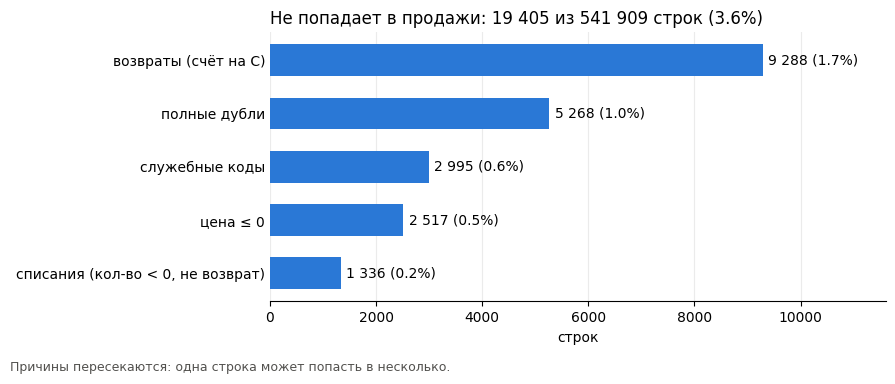

In [89]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#52514e"

flags = {
    "is_dup": "полные дубли",
    "is_cancel": "возвраты (счёт на C)",
    "is_writeoff": "списания (кол-во < 0, не возврат)",
    "is_zero_price": "цена ≤ 0",
    "is_service": "служебные коды",
}

counts = df[list(flags)].sum().rename(flags).sort_values()
bad = df[list(flags)].any(axis=1)

fig, ax = plt.subplots(figsize=(9, 3.8))
bars = ax.barh(counts.index, counts.values, color=BLUE, height=0.6)
ax.bar_label(bars, padding=4, fontsize=10,
             labels=[f"{v:,} ({v / len(df):.1%})".replace(",", " ") for v in counts.values])

ax.set_xlim(0, counts.max() * 1.25)
ax.set_xlabel("строк")
ax.set_title(f"Не попадает в продажи: {bad.sum():,} из {len(df):,} строк ({bad.mean():.1%})".replace(",", " "),
             loc="left", fontsize=12)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
fig.text(0.01, 0.01, "Причины пересекаются: одна строка может попасть в несколько.",
         fontsize=9, color=MUTED)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

сворачиваю продажи до одной строки на заказ

In [90]:
sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]

orders = sales.groupby("InvoiceNo").agg(
    date=("InvoiceDate", "min"),
    customer=("CustomerID", "first"),
    country=("Country", "first"),
    total=("Revenue", "sum"),
    n_lines=("StockCode", "size"),
).reset_index()

orders["is_uk"] = orders["country"] == "United Kingdom"

print(len(orders))
orders.head()

19773


,InvoiceNo,date,customer,country,total,n_lines,is_uk
0,536365,2010-12-01 08:26:00,17850,United Kingdom,139.12,7,True
1,536366,2010-12-01 08:28:00,17850,United Kingdom,22.20,2,True
2,536367,2010-12-01 08:34:00,13047,United Kingdom,278.73,12,True
3,536368,2010-12-01 08:34:00,13047,United Kingdom,70.05,4,True
4,536369,2010-12-01 08:35:00,13047,United Kingdom,17.85,1,True


распределение чека заказа: Великобритания и другие страны

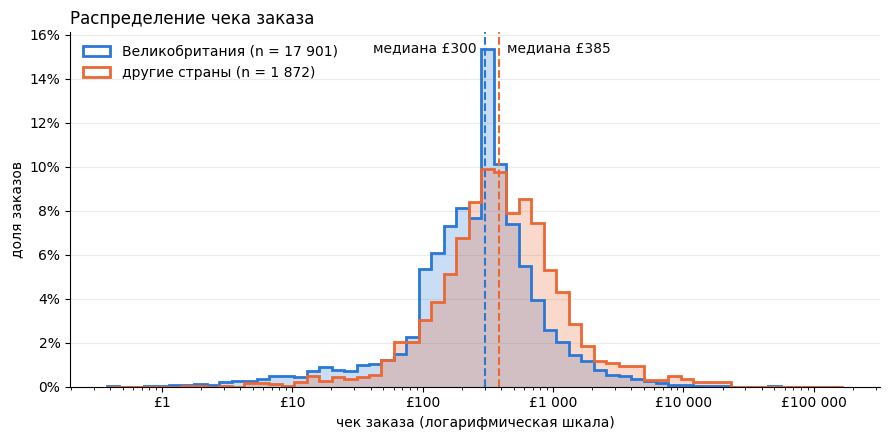

In [91]:
groups = {"Великобритания": (orders.loc[orders["is_uk"], "total"], BLUE),
          "другие страны": (orders.loc[~orders["is_uk"], "total"], ORANGE)}

bins = np.logspace(np.log10(orders["total"].min()), np.log10(orders["total"].max()), 60)

fig, ax = plt.subplots(figsize=(9, 4.5))
for i, (name, (x, color)) in enumerate(groups.items()):
    w = np.full(len(x), 1 / len(x))                       # доля заказов, а не штуки
    ax.hist(x, bins=bins, weights=w, histtype="stepfilled", color=color, alpha=0.25)
    ax.hist(x, bins=bins, weights=w, histtype="step", color=color, lw=2,
            label=f"{name} (n = {len(x):,})".replace(",", " "))
    med = x.median()
    ax.axvline(med, color=color, ls="--", lw=1.5)
    ax.annotate(f"медиана £{med:.0f}", xy=(med, 1), xycoords=("data", "axes fraction"),
                xytext=(-6 if i == 0 else 6, -14), textcoords="offset points",
                ha="right" if i == 0 else "left", fontsize=10, color="#0b0b0b")

ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(
    lambda v, _: f"£{v:,.0f}".replace(",", " ") if v >= 1 else f"£{v:g}"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("чек заказа (логарифмическая шкала)")
ax.set_ylabel("доля заказов")
ax.set_title("Распределение чека заказа", loc="left", fontsize=12)
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

заказы и выручка по месяцам

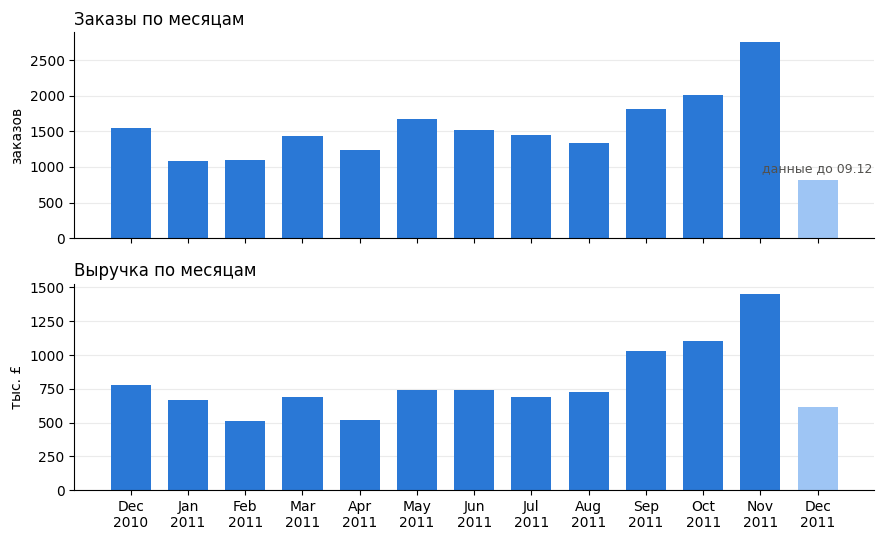

In [ ]:
monthly = orders.groupby(orders["date"].dt.to_period("M")).agg(
    n_orders=("total", "size"), revenue=("total", "sum"))
labels = monthly.index.strftime("%b\n%Y")
last_day = orders["date"].max()
partial = last_day.day < last_day.days_in_month         
colors = [BLUE] * len(monthly)
if partial:
    colors[-1] = "#9ec5f4"

fig, axes = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
axes[0].bar(labels, monthly["n_orders"], color=colors, width=0.7)
axes[0].set_title("Заказы по месяцам", loc="left", fontsize=12)
axes[0].set_ylabel("заказов")
axes[1].bar(labels, monthly["revenue"] / 1000, color=colors, width=0.7)
axes[1].set_title("Выручка по месяцам", loc="left", fontsize=12)
axes[1].set_ylabel("тыс. £")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
if partial:
    axes[0].annotate(f"данные до {last_day:%d.%m}",
                     xy=(len(monthly) - 1, monthly["n_orders"].iloc[-1]),
                     xytext=(0, 6), textcoords="offset points",
                     ha="center", fontsize=9, color=MUTED)
plt.tight_layout()
plt.show()

когда оформляют заказы: день недели и час

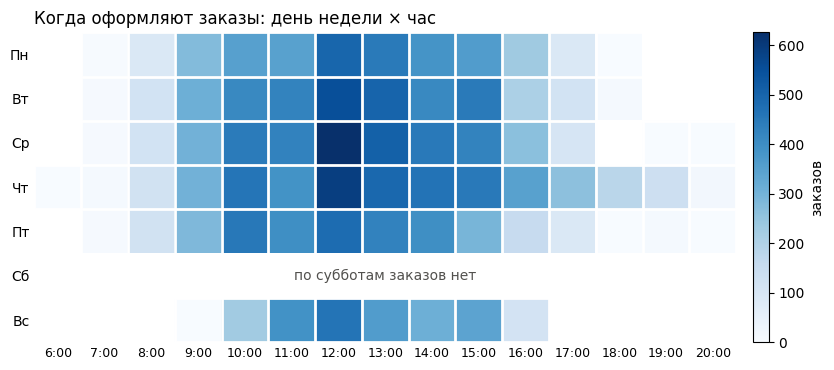

In [93]:
days = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
hours = range(orders["date"].dt.hour.min(), orders["date"].dt.hour.max() + 1)
heat = (pd.crosstab(orders["date"].dt.dayofweek, orders["date"].dt.hour)
          .reindex(index=range(7), columns=hours, fill_value=0))

fig, ax = plt.subplots(figsize=(9, 3.8))
im = ax.imshow(heat.where(heat > 0), cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(len(hours)), [f"{h}:00" for h in hours], fontsize=9)
ax.set_yticks(range(7), days)
ax.set_title("Когда оформляют заказы: день недели × час", loc="left", fontsize=12)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xticks(np.arange(-0.5, len(hours)), minor=True)
ax.set_yticks(np.arange(-0.5, 7), minor=True)
ax.grid(which="minor", color="white", lw=2)
ax.tick_params(which="both", length=0)
fig.colorbar(im, ax=ax, label="заказов", pad=0.02)
if heat.loc[5].sum() == 0:
    ax.text(len(hours) / 2 - 0.5, 5, "по субботам заказов нет",
            ha="center", va="center", fontsize=10, color=MUTED)
plt.tight_layout()
plt.show()

пропуски после чистки

In [94]:
print(sales.isna().sum())

orders["no_customer"] = orders["customer"].isna()
no_cust = orders["no_customer"]

print(f"\nстрок без клиента:   {sales['CustomerID'].isna().mean():.1%}")
print(f"заказов без клиента: {no_cust.mean():.1%}")
print(f"их доля в выручке:   {orders.loc[no_cust, 'total'].sum() / orders['total'].sum():.1%}\n")

print(orders.groupby("no_customer").agg(
    n_orders=("total", "size"),
    median_lines=("n_lines", "median"),
    median_total=("total", "median"),
    share_uk=("is_uk", "mean"),
).round(2))

InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     131354
Country             0
Revenue             0
dtype: int64

строк без клиента:   25.1%
заказов без клиента: 6.9%
их доля в выручке:   14.7%

             n_orders  median_lines  median_total  share_uk
no_customer                                                
False           18402          15.0        301.65      0.90
True             1371          38.0        360.33      0.96


пропуски остались только в CustomerID: это 25% строк, но всего 7% заказов. заказы без клиента длинные (медиана 38 позиций против 15) и чаще британские (96% против 90%), то есть пропуски не случайные.

строки не удаляю: для гипотез на уровне заказа и дня клиент не нужен. в проверках на уровне клиента эти заказы выпадают.

гипотеза 1: осенью спрос выше

спрос = число заказов в торговый день, единица наблюдения - день.
H0: число заказов в день осенью (сентябрь-ноябрь) и в остальные месяцы распределено одинаково.
H1: осенью оно выше.
тест Манна-Уитни, односторонний, alpha = 0.05. размер эффекта: отношение медиан и AUC (вероятность, что случайный осенний день больше случайного неосеннего).

In [95]:
from scipy.stats import mannwhitneyu, chi2_contingency

def mw_greater(x, y):
    """односторонний Манн-Уитни (x больше y): p-value и AUC = P(x > y)"""
    u, p = mannwhitneyu(x, y, alternative="greater")
    return p, u / (len(x) * len(y))

daily = orders.groupby(orders["date"].dt.normalize()).size().rename("n_orders").to_frame()
daily["month"] = daily.index.to_period("M")
daily["is_autumn"] = daily.index.month.isin([9, 10, 11])

autumn = daily.loc[daily["is_autumn"], "n_orders"]
rest = daily.loc[~daily["is_autumn"], "n_orders"]
p, auc = mw_greater(autumn, rest)

print(f"дней: осень {len(autumn)}, остальные {len(rest)}")
print(f"медиана заказов в день: осень {autumn.median():.0f}, остальные {rest.median():.0f} "
      f"(в {autumn.median() / rest.median():.2f} раза)")
print(f"Манн-Уитни: p = {p:.1e}, AUC = {auc:.2f}")
print(f"автокорреляция соседних дней: {daily['n_orders'].autocorr(1):.2f}")

дней: осень 78, остальные 227
медиана заказов в день: осень 82, остальные 56 (в 1.46 раза)
Манн-Уитни: p = 2.1e-16, AUC = 0.81
автокорреляция соседних дней: 0.62


In [96]:
weekly = orders.groupby(orders["date"].dt.to_period("W-SUN")).agg(
    n_orders=("total", "size"),
    n_days=("date", lambda s: s.dt.normalize().nunique()),
)
weekly = weekly[weekly["n_days"] >= 5].copy()
weekly["is_autumn"] = weekly.index.start_time.month.isin([9, 10, 11])

w_autumn = weekly.loc[weekly["is_autumn"], "n_orders"]
w_rest = weekly.loc[~weekly["is_autumn"], "n_orders"]
p, auc = mw_greater(w_autumn, w_rest)

print(f"недель: осень {len(w_autumn)}, остальные {len(w_rest)}")
print(f"медиана заказов в неделю: осень {w_autumn.median():.0f}, остальные {w_rest.median():.0f}")
print(f"Манн-Уитни: p = {p:.1e}, AUC = {auc:.2f}")

dec10 = daily.loc["2010-12-01":"2010-12-09", "n_orders"]
dec11 = daily.loc["2011-12-01":"2011-12-09", "n_orders"]
print(f"\nзаказов в день 1-9 декабря: 2010 - {dec10.mean():.0f}, 2011 - {dec11.mean():.0f}")

недель: осень 13, остальные 36
медиана заказов в неделю: осень 488, остальные 324
Манн-Уитни: p = 2.0e-06, AUC = 0.94

заказов в день 1-9 декабря: 2010 - 104, 2011 - 102


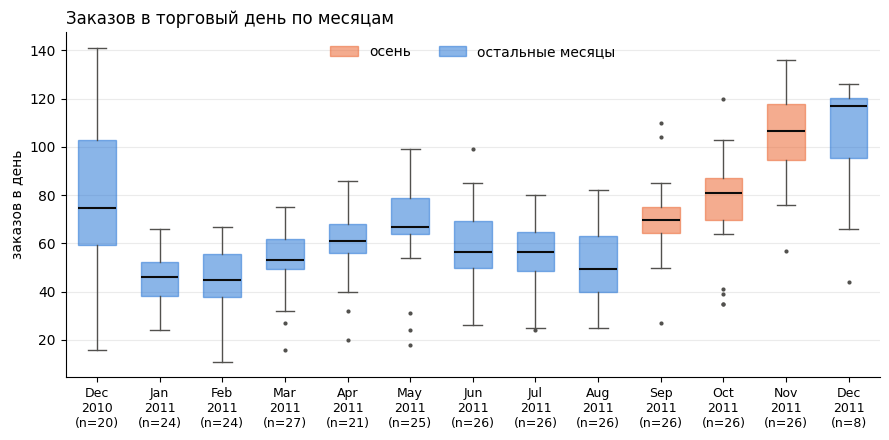

In [97]:
from matplotlib.patches import Patch

months = sorted(daily["month"].unique())
data = [daily.loc[daily["month"] == m, "n_orders"] for m in months]
colors = [ORANGE if m.month in (9, 10, 11) else BLUE for m in months]

fig, ax = plt.subplots(figsize=(9, 4.5))
bp = ax.boxplot(data, patch_artist=True, widths=0.6,
                medianprops={"color": "#0b0b0b", "lw": 1.5},
                flierprops={"marker": "o", "ms": 3, "mfc": MUTED, "mec": "none"},
                whiskerprops={"color": MUTED}, capprops={"color": MUTED})
for box, c in zip(bp["boxes"], colors):
    box.set(facecolor=c, alpha=0.55, edgecolor=c)

ax.set_xticks(range(1, len(months) + 1),
              [f"{m.strftime('%b')}\n{m.year}\n(n={len(d)})" for m, d in zip(months, data)], fontsize=9)
ax.set_ylabel("заказов в день")
ax.set_title("Заказов в торговый день по месяцам", loc="left", fontsize=12)
ax.legend(handles=[Patch(color=ORANGE, alpha=0.55, label="осень"),
                   Patch(color=BLUE, alpha=0.55, label="остальные месяцы")],
          frameon=False, loc="upper center", ncols=2)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

H0 отвергается: осенью медиана 82 заказа в день против 56 (в 1.46 раза), AUC = 0.81, p = 2e-16. по неделям вывод тот же (AUC = 0.94, p = 2e-06).

гипотеза 2: зарубежные клиенты делают заказы с большим чеком

чек считается только по товарам, почтовые сборы убраны при чистке (они стоят в основном в зарубежных заказах). единица наблюдения - заказ.
H0: распределения чека у зарубежных и британских заказов одинаковы.
H1: у зарубежных чек выше.
у чека тяжёлый правый хвост (см. распределение выше), поэтому тест Манна-Уитни, односторонний, alpha = 0.05. размер эффекта: отношение медиан, AUC, бутстрап-интервал для разницы медиан.

In [98]:
uk = orders.loc[orders["is_uk"], "total"]
foreign = orders.loc[~orders["is_uk"], "total"]
p, auc = mw_greater(foreign, uk)

rng = np.random.default_rng(42)
diffs = [np.median(rng.choice(foreign.values, len(foreign))) - np.median(rng.choice(uk.values, len(uk)))
         for _ in range(2000)]
lo, hi = np.percentile(diffs, [2.5, 97.5])

print(f"заказов: зарубежные {len(foreign)}, британские {len(uk)}")
print(f"медиана чека: зарубежные {foreign.median():.0f}, британские {uk.median():.0f} "
      f"(в {foreign.median() / uk.median():.2f} раза)")
print(f"разница медиан: {foreign.median() - uk.median():.0f}, 95% бутстрап-интервал [{lo:.0f}, {hi:.0f}]")
print(f"Манн-Уитни: p = {p:.1e}, AUC = {auc:.2f}")

заказов: зарубежные 1872, британские 17901
медиана чека: зарубежные 385, британские 300 (в 1.29 раза)
разница медиан: 86, 95% бутстрап-интервал [66, 109]
Манн-Уитни: p = 3.6e-56, AUC = 0.61


In [ ]:
customers = (orders.dropna(subset=["customer"])
             .groupby("customer")
             .agg(n_orders=("total", "size"), median_total=("total", "median"), is_uk=("is_uk", "first")))

c_uk = customers.loc[customers["is_uk"], "median_total"]
c_foreign = customers.loc[~customers["is_uk"], "median_total"]
p, auc = mw_greater(c_foreign, c_uk)

print(f"максимум заказов у одного клиента: {customers['n_orders'].max()}")
print(f"клиентов: зарубежные {len(c_foreign)}, британские {len(c_uk)}")
print(f"медиана (по клиентам) медианного чека: зарубежные {c_foreign.median():.0f}, британские {c_uk.median():.0f}")
print(f"Манн-Уитни: p = {p:.1e}, AUC = {auc:.2f}")

максимум заказов у одного клиента: 206
клиентов: зарубежные 418, британские 3916
медиана (по клиентам) медианного чека: зарубежные 368, британские 274
Манн-Уитни: p = 5.9e-22, AUC = 0.64


H0 отвергается: медианный чек зарубежного заказа 385 против 300 у британского (в 1.29 раза), 95% интервал для разницы медиан целиком выше нуля, AUC = 0.61, p = 4e-56.

p-value такой маленький из-за размера выборки, сам эффект умеренный: зарубежный заказ оказывается больше британского в 61% случайных пар. на уровне клиентов (без повторных заказов одного и того же покупателя) вывод тот же: 368 против 274, AUC = 0.64.

гипотеза 3: доля клиентов с возвратами у зарубежных и британских клиентов разная

единица наблюдения - клиент, признак: был ли у него хотя бы один возврат.
H0: доля клиентов с возвратами одинакова в двух группах.
H1: доли различаются (двусторонняя).
критерий хи-квадрат для таблицы 2x2, alpha = 0.05. размер эффекта: разница долей с 95% интервалом.

In [100]:
customers["has_return"] = customers.index.isin(returns["CustomerID"].dropna().unique())

table = pd.crosstab(customers["is_uk"], customers["has_return"])
chi2, p, dof, expected = chi2_contingency(table)

share = customers.groupby("is_uk")["has_return"].mean()
n = customers.groupby("is_uk").size()
diff = share.loc[False] - share.loc[True]
se = np.sqrt((share * (1 - share) / n).sum())

print(table)
print(f"\nдоля клиентов с возвратом: зарубежные {share.loc[False]:.1%}, британские {share.loc[True]:.1%}")
print(f"разница: {diff * 100:.1f}, 95% интервал [{(diff - 1.96 * se) * 100:.1f}, {(diff + 1.96 * se) * 100:.1f}]")
print(f"хи-квадрат = {chi2:.2f}, p = {p:.2f}, минимальная ожидаемая частота {expected.min():.0f}")

has_return  False  True 
is_uk                   
False         264    154
True         2564   1352

доля клиентов с возвратом: зарубежные 36.8%, британские 34.5%
разница: 2.3, 95% интервал [-2.5, 7.2]
хи-квадрат = 0.80, p = 0.37, минимальная ожидаемая частота 145


In [ ]:
return_is_uk = returns.groupby("InvoiceNo")["Country"].first() == "United Kingdom"
invoices = pd.DataFrame({"orders": orders["is_uk"].value_counts(),
                         "returns": return_is_uk.value_counts()})
invoices.index.name = "is_uk"
invoices["share_returns"] = invoices["returns"] / (invoices["orders"] + invoices["returns"])
chi2, p, dof, expected = chi2_contingency(invoices[["orders", "returns"]])

print(invoices.round(3))
print(f"\nхи-квадрат = {chi2:.2f}, p = {p:.4f}")

       orders  returns  share_returns
is_uk                                
True    17901     3029          0.145
False    1872      393          0.174

хи-квадрат = 13.24, p = 0.0003


H0 не отвергается: возврат делали 36.8% зарубежных клиентов и 34.5% британских, p = 0.37.

если считать по счетам, разница выходит "значимой" (17.4% против 14.5%, p = 0.0003), но счета одного клиента зависимы, и несколько активных покупателей дают много наблюдений. доверяю проверке на уровне клиента. это хороший пример того, как единица наблюдения меняет вывод.

итог

1. осенью спрос выше: подтверждается. 82 заказа в день против 56, AUC = 0.81. по сути это предрождественский сезон с сентября по декабрь.
2. зарубежные чеки больше: подтверждается. медиана 385 против 300, эффект умеренный (AUC = 0.61), устойчив на уровне клиентов.
3. доля клиентов с возвратами зависит от страны: не подтверждается, 36.8% против 34.5%, p = 0.37.

ограничения: данные за один год; четверть строк без CustomerID, в проверках на уровне клиента они не участвуют; дневные и недельные наблюдения зависимы.